# КТ 2 — предобработка, чанкинг и метаданные

Отправная точка — сырой корпус КТ 1 (19 665 документов, HTML и эмодзи на месте) и золотой набор
из 50 вопросов. Решения и выводы — в `reports/kt2.md`, здесь — эксперименты и цифры.

**Как считается качество.** Gold размечен на уровне отрывков КТ 1, у каждого доказательства есть дословная
цитата. Чанк содержит доказательство, если в нём лежит непрерывный кусок цитаты не короче половины её слов
(`gigarag.relevance`). Поэтому разметка переносится на любое разбиение и переживает чистку, а удалённый
дубликат передаёт свои доказательства документу, который его заменил.

- **Hit@k** — в топ-k есть хотя бы одно доказательство вопроса;
- **R@k** — доля доказательств вопроса (оценка 2), найденных в топ-k;
- **P@k** — доля чанков топ-k с доказательством (оценка снизу: разметка неполна);
- **MRR** — по первому релевантному чанку в топ-10.

Негативные вопросы доказательств не имеют, в метриках ретрива их нет: остаётся 29 вопросов validation
и 11 test. Все решения принимаются по validation; один вопрос — это 3,4 п. п. Hit@k, поэтому рядом
со средними показано, сколько вопросов конфигурация улучшила и ухудшила.

Каждая конфигурация прогоняется двумя поисковиками: **BM25** (`rank-bm25`, k1 = 1,5, b = 0,75, слова
в нижнем регистре) и **dense BGE-M3** (косинус, fp16 на GPU, до 512 токенов).

In [1]:
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gigarag.chunking
import gigarag.cleaning
import gigarag.noise
import gigarag.patterns
from gigarag import cleaning, llm, metrics, noise, tokens
from gigarag.cache import CacheStore, code_fingerprint, load_or_compute, read_parquet, write_parquet
from gigarag.chunking import ChunkerResources, ChunkerSpec, build_chunker, chunk_length_stats
from gigarag.corpus import Document, read_jsonl
from gigarag.embeddings import load_sentence_model
from gigarag.experiment import Workbench, docs_fingerprint
from gigarag.gold import load_gold

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent  # ноутбук исполняется из notebooks/
DATA = ROOT / "data"
rows, CORPUS_SHA = read_jsonl(DATA / "corpus.jsonl")
raw_docs = tuple(Document(**r) for r in rows)
items = load_gold(ROOT / "gold" / "gold.jsonl")
cache = CacheStore(DATA / "cache" / "kt2", CORPUS_SHA)

BGE_M3, BGE_M3_REV = "BAAI/bge-m3", "5617a9f61b028005a4858fdac845db406aefb181"
E5_SMALL, E5_SMALL_REV = "intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3"
CHONKY, CHONKY_REV = "mirth/chonky_mmbert_small_multilingual_1", "4a92de5574053676cbc5fd06bac86a6e13588000"
MAX_SEQ = 512

tokenizer = tokens.load_tokenizer(BGE_M3, BGE_M3_REV)
encoder = load_sentence_model(BGE_M3, BGE_M3_REV, max_seq_length=MAX_SEQ, half=True)
bench = Workbench(
    cache=cache, items=items, tokenizer=tokenizer, encoder=encoder,
    encoder_params={"model": BGE_M3, "revision": BGE_M3_REV, "max_seq": MAX_SEQ, "half": True},
    code=code_fingerprint(gigarag.patterns, gigarag.cleaning, gigarag.chunking),
)
resources = ChunkerResources(tokenizer)
print(len(raw_docs), "документов, sha256 корпуса:", CORPUS_SHA[:16], "| вопросов:", len(items))

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

19665 документов, sha256 корпуса: 76b0676b841020e9 | вопросов: 50


## 1. Baseline: сырой корпус, TokenChunker(512)

Документы режутся токенами BGE-M3 по 512 без перекрытия — ровно контекст эмбеддера. Никакой чистки:
HTML-разметка статей и постов индексируется как есть.

In [2]:
TOKEN_512 = ChunkerSpec("token", chunk_size=512)


def token_chunks(docs):
    return bench.chunks(docs, TOKEN_512.params(), lambda: build_chunker(TOKEN_512, resources))


raw_chunks, raw_tokens, raw_chunk_seconds = token_chunks(raw_docs)
baseline = bench.run("raw", raw_chunks)
pd.concat({split: metrics.comparison_table(baseline.per_question, split, metrics.METRIC_COLUMNS)
           for split in ("validation", "test")})

retriever          bm25                         dense                        
                  Hit@5   R@5  R@10   P@5   MRR Hit@5   R@5  R@10   P@5   MRR
           config                                                            
validation raw     69.0  37.7  48.1  18.6  56.3  72.4  42.8  44.4  20.0  60.1
test       raw     63.6  35.5  43.0  18.2  53.0  45.5  25.8  30.3  14.5  43.6

Baseline по типам вопросов (validation):

In [3]:
metrics.comparison_table(baseline.per_question.assign(config=baseline.per_question["qtype"]))

retriever  bm25                    dense                  
          Hit@5   R@5  R@10   MRR  Hit@5   R@5  R@10   MRR
config                                                    
factual    63.6  53.0  66.7  55.7   72.7  53.0  53.0  57.6
composite  81.8  41.7  54.4  70.0  100.0  58.3  62.0  88.6
abstract   57.1   7.2   9.1  35.7   28.6   2.4   3.3  19.0

## 2. Предобработка

Шаги применяются по очереди (`gigarag.cleaning.PIPELINE`), после каждого корпус заново режется
TokenChunker(512) и индексируется. Так эффект каждого шага виден отдельно.

- `html` — у статей только тело (`articleBody`), блоки через пустую строку; у остальных теги сняты,
  `<br>` и концы блоков стали переводом строки, сущности декодированы;
- `unicode` — NFKC, невидимые символы (мягкий перенос, zero-width, селекторы эмодзи), пробелы внутри строк,
  лишние пустые строки;
- `urls` — ссылки удалены;
- `emoji` — эмодзи и оформительские символы (•, ►, ✔, `|`, `#`, `@`) удалены; пунктуация и `% + / = < > № ° ×`
  оставлены — они нужны числам патчноутов;
- `signatures` — подписи каналов Telegram: последняя строка поста, повторённая в канале ≥ 20 раз
  (`@Dota2`, «Gabe News | Dota 2»);
- `exact_dup` — пустые документы (медиа без подписи) и точные копии; из копий остаётся самая ранняя;
- `near_dup` — почти-дубликаты как в EDA: кандидаты MinHash LSH (0,5), подтверждение Jaccard ≥ 0,8
  по 3-граммам слов; остаётся самый длинный.

In [4]:
stages = [("raw", cleaning.CleanCorpus(raw_docs)), *cleaning.run_stages(cleaning.CleanCorpus(raw_docs),
                                                                         cleaning.PIPELINE)]
offsets = tokens.offsets_fn(tokenizer)
NOISE_CODE = code_fingerprint(gigarag.patterns, gigarag.noise, gigarag.cleaning)


def class_counts(docs) -> pd.DataFrame:
    """Токены BGE-M3 каждого класса (слово, число, HTML, URL, эмодзи…) по документам."""
    return load_or_compute(
        cache.path("class_counts", "parquet", docs=docs_fingerprint(docs), code=NOISE_CODE, tokenizer=BGE_M3_REV),
        lambda: pd.DataFrame(np.vstack([noise.token_class_counts(d.text, offsets) for d in docs]),
                             columns=noise.CLASS_NAMES).assign(source=[d.source for d in docs]),
        load=read_parquet, save=write_parquet,
    )


stage_rows, stage_results = [], {}
for name, state in stages:
    chunks, chunk_tokens, _ = token_chunks(state.docs)
    stage_results[name] = bench.run(name, chunks, state.aliases)
    counts = class_counts(state.docs)
    shares = noise.class_shares_percent(counts, by="source")
    stage_rows.append({"шаг": name, "документов": len(state.docs),
                       "токенов, млн": counts[noise.CONTENT_CLASSES].sum().sum() / 1e6,
                       "шум, %": noise.removable_noise_percent(shares)["ВСЕГО"], "чанков": len(chunks),
                       "токенов в чанке": chunk_tokens.mean()})
stage_table = pd.DataFrame(stage_rows).set_index("шаг").round(2)
stage_per_q = pd.concat([r.per_question for r in stage_results.values()])
stage_metrics = metrics.comparison_table(stage_per_q)
stage_table.join(stage_metrics.set_axis([" ".join(c) for c in stage_metrics.columns], axis=1))

,документов,"токенов, млн","шум, %",чанков,токенов в чанке,bm25 Hit@5,bm25 R@5,bm25 R@10,bm25 MRR,dense Hit@5,dense R@5,dense R@10,dense MRR
шаг,,,,,,,,,,,,,
raw,19665,9.92,82.49,31033,319.07,69.0,37.7,48.1,56.3,72.4,42.8,44.4,60.1
html,19665,1.89,9.99,20297,91.75,69.0,40.8,43.3,53.5,75.9,48.8,51.8,63.4
unicode,19665,1.87,9.33,20297,90.97,69.0,40.8,43.3,53.5,82.8,49.4,51.8,63.9
urls,19665,1.87,9.30,20295,90.95,69.0,40.8,43.3,53.5,82.8,49.4,51.8,63.9
emoji,19665,1.73,1.88,20286,84.98,69.0,40.8,43.3,53.5,79.3,49.0,52.1,62.0
signatures,19665,1.67,1.93,20284,81.89,69.0,40.5,41.7,46.1,72.4,44.9,50.3,57.5
exact_dup,19464,1.66,1.93,20108,82.23,69.0,40.5,41.7,47.0,72.4,44.9,50.3,57.5
near_dup,19152,1.64,1.95,19796,82.68,69.0,41.2,41.9,47.0,72.4,44.9,50.3,57.5


«Шум» — доля токенов удаляемых классов (HTML, URL, эмодзи, оформительские символы) среди всех непробельных
токенов BGE-M3, как в EDA КТ 1. Сколько вопросов изменил каждый шаг (R@5 относительно предыдущего шага):

In [5]:
pd.concat({name: metrics.paired_changes(stage_per_q, prev, name)
           for (prev, _), (name, _) in pairwise(stages)}, names=["шаг"])

лучше  хуже  без изменений
шаг        retriever                            
html       bm25           4     5             20
           dense          6     2             21
unicode    bm25           0     0             29
           dense          2     0             27
urls       bm25           0     0             29
           dense          0     0             29
emoji      bm25           0     0             29
           dense          0     1             28
signatures bm25           0     1             28
           dense          1     3             25
exact_dup  bm25           0     0             29
           dense          0     0             29
near_dup   bm25           1     0             28
           dense          0     0             29

Дедупликация: сколько отсеяно и куда ушли доказательства gold.

In [6]:
dedup_rows = []
for (_, before), (name, after) in pairwise(stages[-3:]):
    removed = len(before.docs) - len(after.docs)
    empty = sum(not d.text.strip() for d in before.docs) if name == "exact_dup" else 0
    dedup_rows.append({"шаг": name, "было": len(before.docs), "удалено": removed, "из них пустых": empty,
                       "удалено, %": removed / len(before.docs) * 100})
removed_total = len(raw_docs) - len(stages[-1][1].docs)
print(f"всего отсеяно {removed_total} документов ({removed_total / len(raw_docs):.1%} корпуса)")
pd.DataFrame(dedup_rows).set_index("шаг").round(2)

всего отсеяно 513 документов (2.6% корпуса)


,было,удалено,из них пустых,"удалено, %"
шаг,,,,
exact_dup,19665,201,25,1.02
near_dup,19464,312,0,1.60


Контроль для шага `signatures`: весь конвейер без него. Если без подписей поиск хуже, это не значит, что
подписи полезны. Разбор выдачи показал два механических эффекта BM25: посты становятся короче, и нормировка
длины (b = 0,75) поднимает их над патчноутами; слова «Dota 2» из 10 тыс. подписей получают высокий IDF.
Решение принимается по validation сравнением двух полных конвейеров.

In [7]:
no_signatures = [s for s in cleaning.PIPELINE if s.name != "signatures"]
control_state = cleaning.run_stages(cleaning.CleanCorpus(raw_docs), no_signatures)[-1][1]
control = bench.run("все шаги без signatures", token_chunks(control_state.docs)[0], control_state.aliases)
signature_check = pd.concat([stage_results["near_dup"].per_question.assign(config="все шаги"), control.per_question])
display(metrics.comparison_table(signature_check, columns=metrics.METRIC_COLUMNS))
metrics.paired_changes(signature_check, "все шаги без signatures", "все шаги")

retriever                bm25                         dense                        
                        Hit@5   R@5  R@10   P@5   MRR Hit@5   R@5  R@10   P@5   MRR
config                                                                             
все шаги                 69.0  41.2  41.9  17.9  47.0  72.4  44.9  50.3  20.0  57.5
все шаги без signatures  69.0  41.7  43.3  18.6  53.5  79.3  49.0  52.1  23.4  62.6

,лучше,хуже,без изменений
retriever,,,
bm25,0,1,28
dense,1,3,25


## 3. Чанкеры Chonkie

Корпус — после предобработки **без шага `signatures`**: контроль выше показал, что без него validation лучше
по всем метрикам обоих поисковиков. Настройки чанкеров фиксированы и «разумны»,
одинаковы для всех: предел 512 токенов BGE-M3, без перекрытия. Семантические чанкеры ищут границы
по эмбеддингам BGE-M3 (той же модели, что ищет), порог 0,5 — середина сетки ablation (раздел 4).

- **Token** — ровно по 512 токенов.
- **Sentence** — предложения (`. ! ?` и перевод строки) упаковываются до 512 токенов.
- **Recursive** — абзацы → предложения → знаки → слова, до 512.
- **Semantic** — разрез в локальных минимумах сглаженной близости «окно из 3 предложений ↔ следующее».
  В Chonkie 1.7 `threshold` — не косинус, а доля оставляемых минимумов: 0,1 — только самые глубокие провалы,
  0,9 — почти все.
- **SDPM** — Semantic с `skip_window=1`: группа сливается с соседней через одну, если косинус их эмбеддингов
  ≥ `threshold` (в Chonkie 1.7 SDPMChunker стал режимом SemanticChunker).
- **Neural** — NeuralChunker на `chonky_mmbert_small_multilingual_1`: токен-классификатор границ. Модель
  обучена на европейских языках без русского — проверяем, переносится ли.

In [8]:
from gigarag.chunking import neural_chunker
from gigarag.embeddings import memo_embeddings

clean = control_state  # все шаги, кроме signatures
e5_small = load_sentence_model(E5_SMALL, E5_SMALL_REV, max_seq_length=MAX_SEQ, half=True)
boundary_embeddings = {BGE_M3: memo_embeddings(encoder), E5_SMALL: memo_embeddings(e5_small, prefix="query: ")}
resources = ChunkerResources(tokenizer, embeddings=boundary_embeddings.__getitem__,
                             neural_model=lambda: neural_chunker(CHONKY, CHONKY_REV))
chunker_specs = [
    TOKEN_512,
    ChunkerSpec("sentence"),
    ChunkerSpec("recursive"),
    ChunkerSpec("semantic", threshold=0.5, embedder=BGE_M3),
    ChunkerSpec("semantic", threshold=0.5, skip_window=1, embedder=BGE_M3),
    ChunkerSpec("neural", chunk_size=0),
]


def run_chunker(spec: ChunkerSpec, docs=clean.docs, aliases=clean.aliases):
    chunks, chunk_tokens, seconds = bench.chunks(docs, spec.params(), lambda: build_chunker(spec, resources))
    result = bench.run(spec.label, chunks, aliases, chunk_tokens=chunk_tokens)
    stats = {"config": spec.label, **chunk_length_stats(chunk_tokens), "чанкинг, с": seconds,
             "BM25, с": result.seconds["bm25"], "эмбеддинг, с": result.seconds["dense"]}
    return chunks, result, stats


chunker_runs = {spec.label: run_chunker(spec) for spec in chunker_specs}
chunker_stats = pd.DataFrame([stats for _, _, stats in chunker_runs.values()]).set_index("config").round(1)
chunker_per_q = pd.concat([result.per_question for _, result, _ in chunker_runs.values()])
chunker_stats

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/home/mgu/projects/gigaschool-rag/.venv/lib/python3.12/site-packages/chonkie/embeddings/sentence_transformer.py:62: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self._dimension = self.model.get_sentence_embedding_dimension()  # ty: ignore[deprecated]


,chunks,mean,median,std,<50_%,>500_%,"чанкинг, с","BM25, с","эмбеддинг, с"
config,,,,,,,,,
token(512),19724,86.0,53.0,101.0,46.0,3.3,3.6,0.2,15.7
sentence(512),19749,86.3,53.0,99.6,45.7,1.7,5.1,0.3,15.9
recursive(512),19773,86.2,54.0,98.4,45.6,1.1,3.2,0.2,16.0
"semantic(512, t=0.5, bge-m3)",28070,60.7,48.0,53.5,52.0,0.1,101.8,0.3,16.8
"sdpm(512, t=0.5, skip=1, bge-m3)",23604,72.2,50.0,72.9,49.2,0.2,22.1,0.3,16.4
neural(),41374,41.2,17.0,341.8,79.6,0.3,104.9,0.3,17.0


In [9]:
metrics.comparison_table(chunker_per_q)

retriever                         bm25                   dense                  
                                 Hit@5   R@5  R@10   MRR Hit@5   R@5  R@10   MRR
config                                                                          
token(512)                        69.0  41.7  43.3  53.5  79.3  49.0  52.1  62.6
sentence(512)                     69.0  41.7  43.3  53.5  79.3  48.8  52.1  63.4
recursive(512)                    69.0  41.7  44.3  53.2  79.3  48.8  52.1  63.1
semantic(512, t=0.5, bge-m3)      55.2  32.2  41.3  48.5  72.4  47.9  52.0  60.8
sdpm(512, t=0.5, skip=1, bge-m3)  58.6  34.7  45.4  50.0  75.9  49.7  53.0  62.6
neural()                          58.6  32.1  34.2  43.4  69.0  42.9  44.5  54.4

По типам вопросов (validation, R@5):

In [10]:
by_type = metrics.comparison_table(chunker_per_q, columns=["R@5"], by=["config", "qtype"])
by_type.droplevel(1, axis=1).unstack("qtype")

retriever                           bm25                      dense                   
qtype                            factual composite abstract factual composite abstract
config                                                                                
token(512)                          71.2      32.6      9.6    62.1      63.8      5.2
sentence(512)                       71.2      32.6      9.6    62.1      63.8      4.3
recursive(512)                      71.2      32.6      9.6    62.1      63.8      4.3
semantic(512, t=0.5, bge-m3)        53.0      28.9      4.6    62.1      63.0      1.9
sdpm(512, t=0.5, skip=1, bge-m3)    53.0      35.6      4.6    62.1      66.8      3.3
neural()                            53.0      28.9      4.3    62.1      49.5      2.4

**SentenceChunker на постах без знаков препинания.** Пост короче предела любой чанкер оставляет целым,
поэтому важны только длинные посты. Сколько постов Telegram вообще без конца предложения
(`.`, `!`, `?`, `…`) и сколько из них длиннее 512 токенов — только их SentenceChunker мог бы порезать иначе:

In [11]:
telegram = [d for d in clean.docs if d.source.startswith("tg_")]
telegram_tokens = dict(zip([d.doc_id for d in telegram], tokens.token_counts(tokenizer, [d.text for d in telegram]),
                           strict=True))
no_sentence_end = [d for d in telegram if len(gigarag.patterns.sentences(d.text.replace("\n", " "))) == 1]
pd.Series({"постов Telegram": len(telegram), "без конца предложения": len(no_sentence_end),
           "из них длиннее 512 токенов": sum(telegram_tokens[d.doc_id] > 512 for d in no_sentence_end),
           "из них с переводами строк": sum("\n" in d.text for d in no_sentence_end)})

постов Telegram               12964
без конца предложения          2472
из них длиннее 512 токенов        0
из них с переводами строк      2382
dtype: int64

## 4. Ablation семантического чанкинга

**Сетка порогов** — 0,1 / 0,3 / 0,5 / 0,7 / 0,9. В Chonkie 1.7 порог — квантиль локальных минимумов
близости, а не косинус. Поэтому сетка равномерно покрывает весь диапазон: от «режем только по самым
глубоким провалам» до «режем по любому». Пороги по косинусу пришлось бы подбирать под каждую модель:
у e5 близости соседних предложений сидят в 0,8–0,95, у BGE-M3 — в 0,4–0,8.

**Два эмбеддера границ** — `multilingual-e5-small` (118M, быстрый) и `BGE-M3` (568M). Один фактор
за раз: поиск всегда делает BGE-M3, меняется только модель, по которой режется текст.
Эмбеддинги предложений кэшируются в памяти, поэтому время эмбеддинга считается один раз на модель
(у первого порога), остальные пороги — только разрез.

In [12]:
THRESHOLDS = (0.1, 0.3, 0.5, 0.7, 0.9)
ablation_specs = [ChunkerSpec("semantic", threshold=t, embedder=m) for m in (E5_SMALL, BGE_M3) for t in THRESHOLDS]
ablation_runs = {spec.label: (spec, *run_chunker(spec)) for spec in ablation_specs}
ablation = pd.DataFrame([{**stats, "embedder": spec.embedder.split("/")[-1], "threshold": spec.threshold}
                         for spec, _, _, stats in ablation_runs.values()])
ablation_per_q = pd.concat([result.per_question for _, _, result, _ in ablation_runs.values()])
ablation_metrics = metrics.comparison_table(ablation_per_q, columns=["R@5", "R@10", "MRR"])
ablation_metrics.columns = [" ".join(c) for c in ablation_metrics.columns]
ablation_table = ablation.set_index("config")[["embedder", "threshold", "chunks", "mean", "median", "<50_%",
                                               ">500_%", "чанкинг, с"]].join(ablation_metrics).round(1)
ablation_table

,embedder,threshold,chunks,mean,median,<50_%,>500_%,"чанкинг, с",bm25 R@5,bm25 R@10,bm25 MRR,dense R@5,dense R@10,dense MRR
config,,,,,,,,,,,,,,
"semantic(512, t=0.1, multilingual-e5-small)",multilingual-e5-small,0.1,22624,75.3,53.0,46.6,0.7,53.8,35.8,46.5,53.9,46.6,50.3,60.6
"semantic(512, t=0.3, multilingual-e5-small)",multilingual-e5-small,0.3,24635,69.2,52.0,47.4,0.2,5.9,34.3,46.8,45.5,47.3,52.5,60.8
"semantic(512, t=0.5, multilingual-e5-small)",multilingual-e5-small,0.5,28024,60.8,48.0,51.9,0.1,6.0,34.1,43.6,50.1,48.2,52.2,61.6
"semantic(512, t=0.7, multilingual-e5-small)",multilingual-e5-small,0.7,30278,56.3,46.0,54.6,0.0,6.1,33.4,42.8,45.9,46.4,53.0,58.2
"semantic(512, t=0.9, multilingual-e5-small)",multilingual-e5-small,0.9,32515,52.4,43.0,57.1,0.0,6.2,33.4,38.8,46.8,46.4,51.3,57.9
"semantic(512, t=0.1, bge-m3)",bge-m3,0.1,22622,75.3,53.0,46.7,0.6,5.7,35.1,45.8,55.4,47.1,50.7,59.5
"semantic(512, t=0.3, bge-m3)",bge-m3,0.3,24665,69.1,52.0,47.5,0.3,6.2,32.2,45.4,50.2,47.1,52.0,61.1
"semantic(512, t=0.5, bge-m3)",bge-m3,0.5,28070,60.7,48.0,52.0,0.1,101.8,32.2,41.3,48.5,47.9,52.0,60.8
"semantic(512, t=0.7, bge-m3)",bge-m3,0.7,30319,56.2,45.0,54.8,0.0,6.1,33.1,42.2,47.8,47.2,51.6,61.1


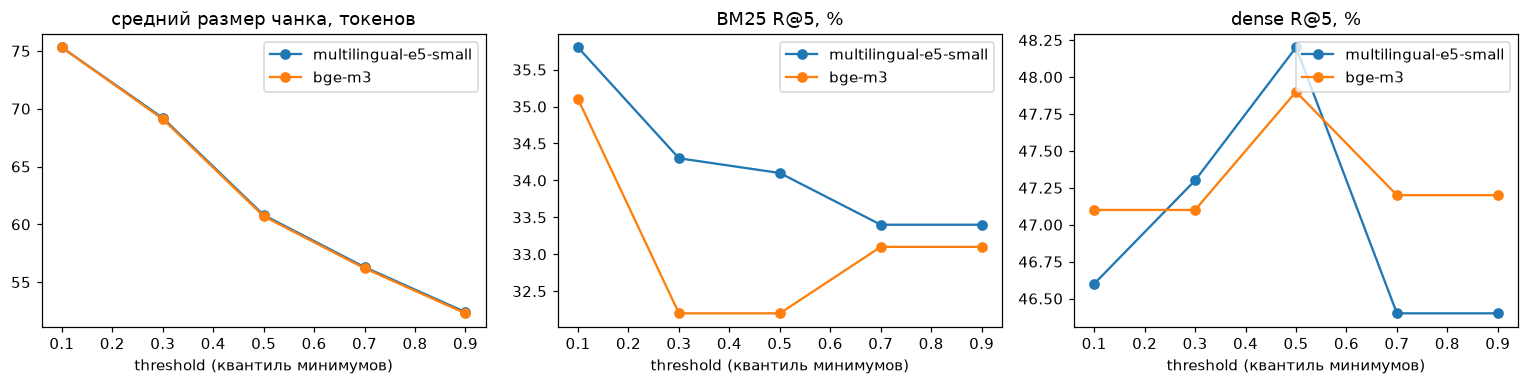

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for embedder, group in ablation_table.groupby("embedder", sort=False):
    axes[0].plot(group["threshold"], group["mean"], marker="o", label=embedder)
    axes[1].plot(group["threshold"], group["bm25 R@5"], marker="o", label=embedder)
    axes[2].plot(group["threshold"], group["dense R@5"], marker="o", label=embedder)
for ax, title in zip(axes, ["средний размер чанка, токенов", "BM25 R@5, %", "dense R@5, %"], strict=True):
    ax.set_title(title)
    ax.set_xlabel("threshold (квантиль минимумов)")
    ax.legend()
plt.tight_layout()

**Как выбор модели меняет разбиение.** Для каждого документа, который хоть одна модель разрезала,
сравниваем множества границ при одном пороге: доля общих границ (Jaccard) и число чанков.

In [14]:
from gigarag.chunking import boundary_agreement

agreement_rows = []
for threshold in THRESHOLDS:
    e5_chunks = ablation_runs[ChunkerSpec("semantic", threshold=threshold, embedder=E5_SMALL).label][1]
    bge_chunks = ablation_runs[ChunkerSpec("semantic", threshold=threshold, embedder=BGE_M3).label][1]
    agreement_rows.append({"threshold": threshold, **boundary_agreement(e5_chunks, bge_chunks)})
pd.DataFrame(agreement_rows).set_index("threshold").round(3)

,разрезанных документов,Jaccard границ,чанков A,чанков B
threshold,,,,
0.1,2530,0.463,2.402,2.401
0.3,2530,0.460,3.196,3.208
0.5,2530,0.508,4.536,4.554
0.7,2530,0.529,5.427,5.443
0.9,2530,0.551,6.311,6.338


**Визуализация.** Один и тот же текст — раздел статьи dota2.ru о патче — при трёх порогах и двух моделях.
Каждая строка — предложение, цвет — номер чанка: смена цвета — граница.

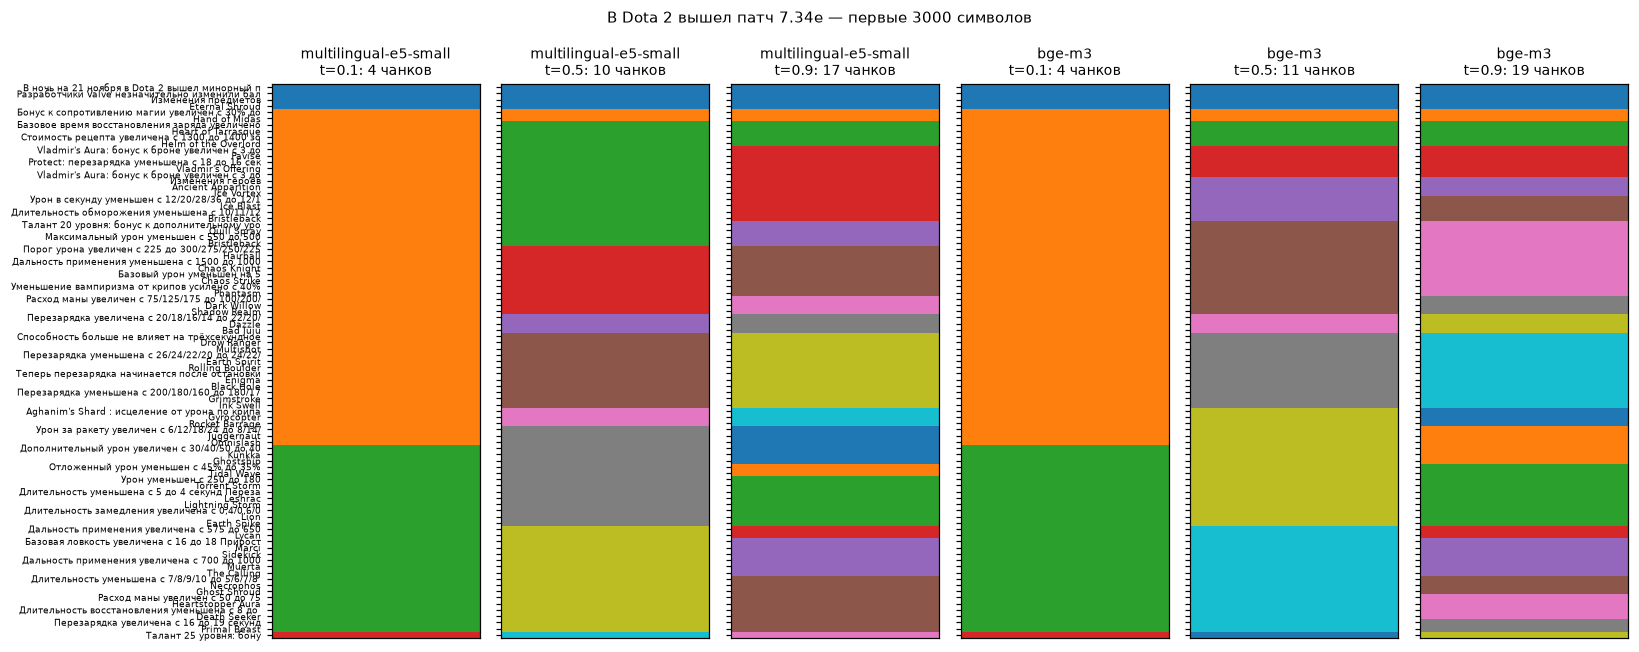

In [15]:
from gigarag.chunking import sentence_chunk_labels

example_doc = min((d for d in clean.docs if d.source == "dota2ru_article" and len(d.text) > 3000),
                  key=lambda d: len(d.text))
example_text = example_doc.text[:3000]
fig, axes = plt.subplots(1, 6, figsize=(15, 6), sharey=True)
for col, (model, threshold) in enumerate([(m, t) for m in (E5_SMALL, BGE_M3) for t in (0.1, 0.5, 0.9)]):
    spec = ChunkerSpec("semantic", threshold=threshold, embedder=model)
    pieces = build_chunker(spec, resources)([example_text])[0]
    labels, sentences = sentence_chunk_labels(example_text, pieces)
    axes[col].imshow(np.array(labels)[:, None] % 10, cmap="tab10", aspect="auto", vmin=0, vmax=9)
    axes[col].set_title(f"{model.split('/')[-1]}\nt={threshold}: {len(pieces)} чанков", fontsize=9)
    axes[col].set_xticks([])
axes[0].set_yticks(range(len(sentences)))
axes[0].set_yticklabels([s[:45] for s in sentences], fontsize=6)
plt.suptitle(f"{example_doc.title[:80]} — первые 3000 символов", fontsize=10)
plt.tight_layout()

In [16]:
pieces_low = build_chunker(ChunkerSpec("semantic", threshold=0.1, embedder=BGE_M3), resources)([example_text])[0]
pieces_high = build_chunker(ChunkerSpec("semantic", threshold=0.9, embedder=BGE_M3), resources)([example_text])[0]
print("=== BGE-M3, t=0.1 ===")
print("\n--- ✄ ---\n".join(p.strip()[:300] for p in pieces_low[:4]))
print("\n=== BGE-M3, t=0.9 ===")
print("\n--- ✄ ---\n".join(p.strip()[:300] for p in pieces_high[:8]))

=== BGE-M3, t=0.1 ===
В ночь на 21 ноября в Dota 2 вышел минорный патч 7.34e. Разработчики Valve незначительно изменили баланс героев, а также предметов.

Изменения предметов

Eternal Shroud
--- ✄ ---
Бонус к сопротивлению магии увеличен с 30% до 35%

Hand of Midas

Базовое время восстановления заряда увеличено со 100 до 110 секунд

Heart of Tarrasque

Стоимость рецепта увеличена с 1300 до 1400 золота (общая стоимость увеличилась с 5100 до 5200 золота) Бонус к силе уменьшен с 40 до 35

Helm of th
--- ✄ ---
Дополнительный урон увеличен с 30/40/50 до 40/45/50

Kunkka

Ghostship

Отложенный урон уменьшен с 45% до 35%

Tidal Wave

Урон уменьшен с 250 до 180

Torrent Storm

Длительность уменьшена с 5 до 4 секунд Перезарядка увеличена с 70 до 75 секунд

Leshrac

Lightning Storm

Длительность замедления увел
--- ✄ ---
Талант 25 уровня: бону

=== BGE-M3, t=0.9 ===
В ночь на 21 ноября в Dota 2 вышел минорный патч 7.34e. Разработчики Valve незначительно изменили баланс героев, а также предметов.

### Размер чанка для отобранного кандидата

Recursive и Sentence лучше остальных и почти равны; дальше — Recursive: он режет по абзацам, а в корпусе
абзац — естественная единица (блок патчноута, раздел статьи). Единственный гиперпараметр — предел размера.
1024 не пробуем: BGE-M3 эмбеддит не больше 512 токенов, и хвост большого чанка dense-поиск не увидел бы.

In [17]:
size_specs = [ChunkerSpec("recursive", chunk_size=size) for size in (128, 256, 512)]
size_runs = {spec.label: run_chunker(spec) for spec in size_specs}
size_per_q = pd.concat([result.per_question for _, result, _ in size_runs.values()])
size_metrics = metrics.comparison_table(size_per_q)
size_metrics.columns = [" ".join(c) for c in size_metrics.columns]
pd.DataFrame([stats for _, _, stats in size_runs.values()]).set_index("config")[
    ["chunks", "mean", "median", "<50_%", ">500_%"]].join(size_metrics).round(1)

,chunks,mean,median,<50_%,>500_%,bm25 Hit@5,bm25 R@5,bm25 R@10,bm25 MRR,dense Hit@5,dense R@5,dense R@10,dense MRR
config,,,,,,,,,,,,,
recursive(128),26083,65.3,59.0,41.3,0.0,55.2,33.5,37.8,46.5,79.3,49.3,53.6,64.4
recursive(256),21126,80.6,56.0,43.3,0.0,62.1,37.4,44.7,47.1,79.3,49.9,53.3,64.0
recursive(512),19773,86.2,54.0,45.6,1.1,69.0,41.7,44.3,53.2,79.3,48.8,52.1,63.1


In [18]:
BEST = ChunkerSpec("recursive", chunk_size=512)
best_chunks, best_result, best_stats = run_chunker(BEST)
best_tokens = bench.chunks(clean.docs, BEST.params(), lambda: build_chunker(BEST, resources))[1]
print("лучший простой чанкер:", BEST.label, "| чанков:", len(best_chunks))

лучший простой чанкер: recursive(512) | чанков: 19773


## 5. ParentDocumentRetriever

Родитель — Recursive-чанк размера P (абзацы целиком), ребёнок — Token-чанк размера C внутри родителя.
Индексируются дети (BGE-M3 и BM25), выдаются родители: score родителя — лучший score его детей,
повторы схлопываются. Мелкий ребёнок точнее эмбеддится, крупный родитель отдаёт генератору контекст.
Родитель длиннее 512 токенов не эмбеддится сам, поэтому P может быть больше контекста BGE-M3.

In [19]:
from gigarag.chunking import child_chunks
from gigarag.experiment import Entries

PARENT_CHILD = [(512, 128), (1024, 128), (1024, 256), (2048, 256)]
parent_runs, parent_stats = {}, []
for parent_size, child_size in PARENT_CHILD:
    parent_spec = ChunkerSpec("recursive", chunk_size=parent_size)
    child_spec = ChunkerSpec("token", chunk_size=child_size)
    parents, parent_tokens, parent_seconds = bench.chunks(clean.docs, parent_spec.params(),
                                                          lambda s=parent_spec: build_chunker(s, resources))
    children, owners = child_chunks(parents, build_chunker(child_spec, resources))
    config = f"parent {parent_size} / child {child_size}"
    result = bench.run(config, parents, clean.aliases, entries=Entries([c.text for c in children], owners),
                       chunk_tokens=parent_tokens)
    parent_runs[config] = (parents, parent_tokens, result)
    parent_stats.append({"config": config, "родителей": len(parents), "детей": len(children),
                         "токенов в родителе": parent_tokens.mean(), "чанкинг, с": parent_seconds,
                         "эмбеддинг детей, с": result.seconds["dense"]})
parent_per_q = pd.concat([best_result.per_question, *(r.per_question for _, _, r in parent_runs.values())])
parent_metrics = metrics.comparison_table(parent_per_q)
parent_metrics.columns = [" ".join(c) for c in parent_metrics.columns]
pd.DataFrame(parent_stats).set_index("config").round(1).join(parent_metrics, how="right")

,родителей,детей,токенов в родителе,"чанкинг, с","эмбеддинг детей, с",bm25 Hit@5,bm25 R@5,bm25 R@10,bm25 MRR,dense Hit@5,dense R@5,dense R@10,dense MRR
config,,,,,,,,,,,,,
recursive(512),NaN,NaN,NaN,NaN,NaN,69.0,41.7,44.3,53.2,79.3,48.8,52.1,63.1
parent 512 / child 128,19773.0,24902.0,86.2,3.2,17.0,62.1,38.8,48.0,47.3,79.3,48.3,54.9,62.4
parent 1024 / child 128,19372.0,24816.0,87.9,5.3,16.7,62.1,38.8,48.0,47.4,79.3,48.3,54.9,62.7
parent 1024 / child 256,19372.0,20938.0,87.9,5.3,17.2,69.0,41.7,45.5,49.4,79.3,49.0,53.3,62.3
parent 2048 / child 256,19209.0,20915.0,88.7,4.9,17.1,69.0,41.7,45.5,49.4,79.3,49.4,53.6,62.3


По типам вопросов: R@5 на validation относительно лучшего простого чанкера и сколько токенов контекста
в среднем занимают топ-5 (`tokens@5`): выигрыш родителей отчасти покупается объёмом.

In [20]:
parent_by_type = metrics.comparison_table(parent_per_q, columns=["R@5"], by=["config", "qtype"])
display(parent_by_type.droplevel(1, axis=1).unstack("qtype"))
parent_per_q[parent_per_q["split"] == "validation"].groupby(["config", "retriever"], sort=False)[
    "tokens@5"].mean().unstack("retriever").round(0)

retriever                  bm25                      dense                   
qtype                   factual composite abstract factual composite abstract
config                                                                       
recursive(512)             71.2      32.6      9.6    62.1      63.8      4.3
parent 512 / child 128     62.1      37.4      4.4    62.1      62.0      5.2
parent 1024 / child 128    62.1      37.4      4.4    62.1      62.0      5.2
parent 1024 / child 256    71.2      32.6      9.6    62.1      63.8      5.2
parent 2048 / child 256    71.2      32.6      9.6    62.1      63.8      6.7

retriever,bm25,dense
config,,
recursive(512),370.0,660.0
parent 512 / child 128,558.0,654.0
parent 1024 / child 128,749.0,804.0
parent 1024 / child 256,470.0,924.0
parent 2048 / child 256,557.0,1415.0


## 6. Метаданные

Извлекаются для чанков лучшего простого чанкера (`gigarag.metadata.chunk_metadata`):

- **структурные** — дата, источник, патч (у постов Telegram — патч, действовавший на дату поста),
  длина документа в токенах, позиция чанка (номер и относительная позиция);
- **контентные** — тип (патчноут / статья / комментарий / пост / офтоп), язык по доле латиницы
  (ru ≤ 20% < mixed < 60% ≤ en), топ-5 ключевых слов по TF-IDF;
- **качественный** — шумовой score: доля неалфавитных токенов BGE-M3 (числа, знаки, эмодзи) среди непробельных.

Ключевые слова — TF-IDF, а не KeyBERT: на 20 тыс. чанков он считается за секунды и детерминирован.
Для коротких постов KeyBERT выбирал бы фразы из тех же 20–50 слов.

In [21]:
import gigarag.metadata
from gigarag import metadata

doc_token_counts = dict(zip([d.doc_id for d in clean.docs],
                            tokens.token_counts(tokenizer, [d.text for d in clean.docs]), strict=True))
meta = load_or_compute(
    cache.path("chunk_meta", "parquet", docs=docs_fingerprint(clean.docs), chunker=BEST.label,
               code=code_fingerprint(gigarag.metadata, gigarag.noise, gigarag.patterns), tokenizer=BGE_M3_REV),
    lambda: metadata.chunk_metadata(best_chunks, clean.docs, doc_token_counts, offsets),
    load=read_parquet, save=write_parquet,
)
meta.sample(6, random_state=42)[["chunk_id", "source", "date", "patch", "doc_tokens", "position", "content_type",
                                 "language", "noise_score", "keywords"]]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (14924 > 8192). Running this sequence through the model will result in indexing errors


,chunk_id,source,date,patch,doc_tokens,position,content_type,language,noise_score,keywords
8703,tg:Dota2/20501@0,tg_Dota2,2025-03-07,7.38b,36,0,пост,ru,0.083333,"[торрента, торнадо, пользуйтесь, кемпы, стакать]"
10633,tg:Dota2/25241@0,tg_Dota2,2025-12-08,7.39e,55,0,пост,mixed,0.145455,"[servant, shadow, задействован, выбирали, promulgate]"
7917,tg:Dota2/17785@0,tg_Dota2,2024-09-15,7.37c,37,0,пост,mixed,0.135135,"[душат, выжить, плохой, сларк, файт]"
6415,dota2ru:comment:1724772@0,dota2ru_comment,2026-03-25,7.41,20,0,комментарий,mixed,0.100000,"[муэрта, hydra, breath, предметом, новым]"
15185,tg:gabenews/8459@0,tg_gabenews,2024-04-21,7.35d,220,0,пост,mixed,0.113636,"[falcons, team, sumail, персонажей, свапов]"
5412,dota2ru:comment:1660237@0,dota2ru_comment,2025-02-19,7.38,4,0,комментарий,en,0.000000,[juggernaut]


In [22]:
meta.groupby("content_type").agg(чанков=("chunk_id", "size"), шум_медиана=("noise_score", "median"),
                                 ru=("language", lambda s: (s == "ru").mean() * 100),
                                 mixed=("language", lambda s: (s == "mixed").mean() * 100),
                                 en=("language", lambda s: (s == "en").mean() * 100)).round(2)

,чанков,шум_медиана,ru,mixed,en
content_type,,,,,
комментарий,2645,0.11,96.94,2.46,0.60
офтоп,2223,0.13,56.37,41.75,1.89
патчноут,3498,0.29,39.39,60.61,0.00
пост,10765,0.13,59.68,39.54,0.77
статья,642,0.23,49.84,50.00,0.16


Шумовой score у патчноутов самый высокий: в правке «с 30% до 35%» числа и знаки — суть, а не мусор.
Поэтому фильтр «выбросить шумные чанки» опасен — проверяем его ниже вместе с полезными фильтрами.

### Применение 1: фильтрация при ретриве

Фильтр — маска допустимых чанков до выбора топ-k. Три сценария:

- **по патчу** — если вопрос называет патч («7.36c»), остаются чанки этого патча или упоминающие его
  в тексте. Номер патча берётся из самого запроса — никакой подсказки из gold;
- **без офтопа** — нетематические посты Telegram (20% от тематических, оставлены в КТ 1 как шум) исключены;
- **без шумных** — чанки с шумовым score > 0,5 исключены.

Precision считается только на вопросах, к которым фильтр применим.

In [23]:
best_texts = [c.text for c in best_chunks]
filters = {
    "фильтр по патчу": metadata.patch_filter(meta, best_texts),
    "без офтопа": metadata.drop_types_filter(frozenset({metadata.OFFTOPIC})),
    "без шумных (score > 0,5)": metadata.max_noise_filter(0.5),
}
filter_rows = []
filter_runs = {}
for name, chunk_filter in filters.items():
    masks = metadata.filter_masks(chunk_filter, meta, bench.queries)
    filtered = bench.run(name, best_chunks, clean.aliases, masks=masks, chunk_tokens=best_tokens)
    filter_runs[name] = filtered
    applies = best_result.per_question["qid"].isin(masks)
    before = best_result.per_question[applies].assign(config="без фильтра")
    after = filtered.per_question[filtered.per_question["qid"].isin(masks)]
    table = metrics.comparison_table(pd.concat([before, after]), columns=["P@5", "R@5", "Hit@5", "MRR"])
    table.index = pd.MultiIndex.from_tuples([(name, cfg) for cfg in table.index], names=["фильтр", "выдача"])
    table[("вопросов", "")] = before.query("split == 'validation'")["qid"].nunique()
    filter_rows.append(table)
pd.concat(filter_rows)

retriever                                          bm25                   dense                   вопросов
                                                    P@5   R@5 Hit@5   MRR   P@5   R@5 Hit@5   MRR         
фильтр                   выдача                                                                           
фильтр по патчу          без фильтра               17.9  34.9  68.4  50.3  24.2  44.5  78.9  64.3       19
                         фильтр по патчу           22.1  41.8  68.4  63.5  26.3  52.2  84.2  82.3       19
без офтопа               без фильтра               18.6  41.7  69.0  53.2  22.8  48.8  79.3  63.1       29
                         без офтопа                19.3  41.9  72.4  56.5  22.8  48.8  79.3  63.4       29
без шумных (score > 0,5) без фильтра               18.6  41.7  69.0  53.2  22.8  48.8  79.3  63.1       29
                         без шумных (score > 0,5)  16.6  39.1  62.1  46.3  20.7  46.3  75.9  62.0       29

### Применение 2: метаданные в тексте чанка (prepend)

Перед индексированием к чанку добавляется строка «заголовок документа | тип | патч | дата». Комментарий
или кусок статьи сам по себе не называет патч и тему — префикс их добавляет. Выдаётся и оценивается
тот же чанк, меняется только индексируемый текст.

In [24]:
prefixed = [metadata.with_metadata_prefix(text, row) for text, row in zip(best_texts, meta.to_dict("records"),
                                                                           strict=True)]
print(prefixed[next(i for i, c in enumerate(best_chunks) if c.doc_id.startswith("dota2ru:comment"))][:300])
prepend = bench.run("prepend метаданных", best_chunks, clean.aliases,
                    entries=Entries(prefixed, list(range(len(best_chunks)))), chunk_tokens=best_tokens)
prepend_per_q = pd.concat([best_result.per_question, prepend.per_question])
display(metrics.comparison_table(prepend_per_q, columns=metrics.METRIC_COLUMNS))
display(metrics.paired_changes(prepend_per_q, BEST.label, "prepend метаданных"))
metrics.comparison_table(prepend_per_q, columns=["R@5"], by=["config", "qtype"]).droplevel(1, axis=1).unstack("qtype")

Комментарий к «В Dota 2 вышел патч 7.34» | комментарий | патч 7.34 | 2023-08-09
Шардовый контрспелл, который по задумке придуман для союзников, почему-то можно кинуть на врага, и он отразит абилку в ваших союзников.

Например, Дум.

EDIT: Пофиксили через час-полтора. Но было забавно.


retriever           bm25                         dense                        
                   Hit@5   R@5  R@10   P@5   MRR Hit@5   R@5  R@10   P@5   MRR
config                                                                        
recursive(512)      69.0  41.7  44.3  18.6  53.2  79.3  48.8  52.1  22.8  63.1
prepend метаданных  62.1  40.2  44.8  17.2  55.2  82.8  53.3  58.7  26.2  73.0

,лучше,хуже,без изменений
retriever,,,
bm25,0,3,26
dense,5,0,24


retriever             bm25                      dense                   
qtype              factual composite abstract factual composite abstract
config                                                                  
recursive(512)        71.2      32.6      9.6    62.1      63.8      4.3
prepend метаданных    71.2      30.8      6.3    66.7      66.8     11.0

## 7. LLM-обработка чанков

Модель `deepseek-flash` (DeepSeek-V4.1-Flash, дешёвая массовая обработка), t = 0, по одному чанку на запрос,
промпты — `gigarag.enrich` (версия 1). Обрабатываются чанки от 30 токенов: резюме реплики «+1» или вопросы
к подписи из трёх слов ничего не дают. Короткие чанки в обоих вариантах индексируются своим текстом.

- **Суммаризация** — индексируется резюме вместо текста чанка.
- **Гипотетические вопросы** — 3 вопроса на чанк, каждый — отдельная запись индекса; score чанка — лучший
  из его вопросов.

Выдаётся и оценивается исходный чанк: релевантность — по цитате в его тексте.

Стоимость — по пиковому тарифу DeepSeek (оценка сверху, вне пика вдвое дешевле). `deepseek-flash` —
рассуждающая модель: выходные токены включают рассуждения, поэтому их больше, чем самого текста ответа.
Время — первый прогон в 32 потока.

In [25]:
import gigarag.enrich
from gigarag import enrich
from gigarag.cache import load_or_compute_timed, read_json, write_json
from gigarag.experiment import texts_fingerprint
from gigarag.llm import CachedChat, OpenAIChat

chat = CachedChat(OpenAIChat.from_env(ROOT / ".env", enrich.PROVIDER, enrich.PROVIDER_BASE_URL), DATA / "llm_cache")
llm_targets = enrich.eligible(best_tokens)
print(f"в LLM идут {len(llm_targets)} чанков из {len(best_chunks)} ({len(llm_targets) / len(best_chunks):.0%})")
ENRICH_CODE = code_fingerprint(gigarag.enrich)


def enrich_all(name: str, make_request):
    """Ответы LLM на все отобранные чанки и время первого прогона (повторный — из кэша запросов)."""
    def compute():
        responses = enrich.complete_all(chat, [make_request(best_texts[i]) for i in llm_targets])
        return [{"content": r.content, "prompt_tokens": r.prompt_tokens, "completion_tokens": r.completion_tokens}
                for r in responses]
    path = cache.path(f"llm_{name}", "json", texts=texts_fingerprint([best_texts[i] for i in llm_targets]),
                      code=ENRICH_CODE)
    return load_or_compute_timed(path, compute, load=read_json, save=write_json)


summaries, summary_seconds = enrich_all("summary", enrich.summary_request)
questions, questions_seconds = enrich_all("questions", enrich.questions_request)
llm_usage = pd.DataFrame([
    {"обработка": name, "запросов": len(records), "входных токенов": sum(r["prompt_tokens"] for r in records),
     "выходных токенов": sum(r["completion_tokens"] for r in records), "время, мин": seconds / 60,
     "стоимость, $": enrich.Usage(len(records), sum(r["prompt_tokens"] for r in records),
                                  sum(r["completion_tokens"] for r in records), 0).cost_usd}
    for name, records, seconds in [("суммаризация", summaries, summary_seconds),
                                   ("вопросы", questions, questions_seconds)]
]).set_index("обработка").round(2)
llm_usage

в LLM идут 16014 чанков из 19773 (81%)


,запросов,входных токенов,выходных токенов,"время, мин","стоимость, $"
обработка,,,,,
суммаризация,16014,4459387,7340429,18.62,10.15
вопросы,16014,5067919,9176422,35.86,12.53


In [26]:
summary_text = dict(zip(llm_targets, (r["content"].strip() for r in summaries), strict=True))
summary_entries = Entries([summary_text.get(i, text) for i, text in enumerate(best_texts)],
                          list(range(len(best_chunks))))
chunk_questions = dict(zip(llm_targets, (enrich.parse_questions(r["content"]) for r in questions), strict=True))
question_pairs = [(q, i) for i, text in enumerate(best_texts) for q in chunk_questions.get(i) or [text]]
question_entries = Entries([q for q, _ in question_pairs], [i for _, i in question_pairs])
broken_json = sum(not llm.is_json_object(r["content"]) for r in questions)
no_questions = sum(not chunk_questions[i] for i in llm_targets)
print(f"Ответов без вопросов — {no_questions} из {len(llm_targets)}: битый JSON — {broken_json}, "
      f"остальные — отказ модели (пустой список, «фрагмент не про Dota»). Такие чанки индексируются своим текстом")
example = llm_targets[len(llm_targets) // 2]
print("ЧАНК:", best_texts[example][:400], "\n\nРЕЗЮМЕ:", summary_text[example],
      "\n\nВОПРОСЫ:", chunk_questions[example])

Ответов без вопросов — 124 из 16014: битый JSON — 89, остальные — отказ модели (пустой список, «фрагмент не про Dota»). Такие чанки индексируются своим текстом
ЧАНК: Лучшая шмотка на саппорта?

Игрок с Reddit сделал руководство по предметам, которые стоит покупать на героях поддержки

Теперь вы знаете, что купить

Dota2 

РЕЗЮМЕ: На Reddit игрок составил руководство по предметам, которые стоит покупать на героях поддержки. Материал озаглавлен вопросом о лучшей шмотке на саппорта и завершается фразой «Теперь вы знаете, что купить». 

ВОПРОСЫ: ['Кто сделал руководство по предметам для героев поддержки в Dota 2?', 'О чём руководство игрока с Reddit: какие предметы покупать на саппортах?', 'Существует ли гайд по закупке предметов на героях поддержки в Dota 2?']


In [27]:
summary_run = bench.run("резюме вместо текста", best_chunks, clean.aliases, entries=summary_entries,
                        chunk_tokens=best_tokens)
questions_run = bench.run("вопросы вместо текста", best_chunks, clean.aliases, entries=question_entries,
                          chunk_tokens=best_tokens)
llm_per_q = pd.concat([best_result.per_question, summary_run.per_question, questions_run.per_question])
display(metrics.comparison_table(llm_per_q, columns=metrics.METRIC_COLUMNS))
display(pd.concat({name: metrics.paired_changes(llm_per_q, BEST.label, name)
                   for name in ("резюме вместо текста", "вопросы вместо текста")}))
metrics.comparison_table(llm_per_q, columns=["R@5"], by=["config", "qtype"]).droplevel(1, axis=1).unstack("qtype")

retriever              bm25                         dense                        
                      Hit@5   R@5  R@10   P@5   MRR Hit@5   R@5  R@10   P@5   MRR
config                                                                           
recursive(512)         69.0  41.7  44.3  18.6  53.2  79.3  48.8  52.1  22.8  63.1
резюме вместо текста   62.1  34.6  45.2  17.2  46.7  75.9  44.7  55.0  22.1  66.7
вопросы вместо текста  51.7  27.4  37.7  13.8  44.3  72.4  45.2  49.5  21.4  57.1

лучше  хуже  без изменений
                      retriever                            
резюме вместо текста  bm25           3     4             22
                      dense          1     2             26
вопросы вместо текста bm25           2     8             19
                      dense          3     5             21

retriever                bm25                      dense                   
qtype                 factual composite abstract factual composite abstract
config                                                                     
recursive(512)           71.2      32.6      9.6    62.1      63.8      4.3
резюме вместо текста     53.0      29.5     13.7    53.0      60.8      6.2
вопросы вместо текста    34.8      35.6      2.7    48.5      63.8     10.8

## 8. Итоговая таблица

Строка — конфигурация «предобработка + чанкер + метаданные + LLM». Validation и test — отдельно;
test не участвовал ни в одном выборе. Лучший порог семантического чанкинга и лучшая пара parent/child
выбираются здесь же по validation (средний R@5 двух поисковиков). Время индексирования, с — чанкинг
с подсчётом токенов + построение BM25 + эмбеддинг всех записей BGE-M3 на RTX 5080 (+ LLM-обработка, где она есть).

In [28]:
def mean_r5(per_q: pd.DataFrame, config: str) -> float:
    """Критерий выбора внутри серии: средний R@5 двух поисковиков на validation."""
    subset = per_q[(per_q["split"] == "validation") & (per_q["config"] == config)]
    return subset.groupby("retriever")["R@5"].mean().mean()


best_semantic = max(ablation_specs, key=lambda spec: mean_r5(ablation_per_q, spec.label))
best_parent = max(parent_runs, key=lambda config: mean_r5(parent_per_q, config))
print("лучший порог семантического:", best_semantic.label, "| лучший parent/child:", best_parent)

CLEANED = "все шаги, кроме signatures"
parent_info = pd.DataFrame(parent_stats).set_index("config").loc[best_parent]
token_stats, sdpm_spec = chunker_runs[TOKEN_512.label][2], chunker_specs[4]
semantic_stats, sdpm_stats = ablation_runs[best_semantic.label][3], chunker_runs[sdpm_spec.label][2]
final_configs = [  # (предобработка, чанкер, метаданные, LLM, прогон, средний размер чанка, время подготовки чанков, с)
    ("нет", TOKEN_512.label, "—", "—", baseline, raw_tokens.mean(), raw_chunk_seconds),
    (CLEANED, TOKEN_512.label, "—", "—", chunker_runs[TOKEN_512.label][1], token_stats["mean"],
     token_stats["чанкинг, с"]),
    (CLEANED, BEST.label, "—", "—", best_result, best_stats["mean"], best_stats["чанкинг, с"]),
    (CLEANED, best_semantic.label, "—", "—", ablation_runs[best_semantic.label][2], semantic_stats["mean"],
     semantic_stats["чанкинг, с"]),
    (CLEANED, sdpm_spec.label, "—", "—", chunker_runs[sdpm_spec.label][1], sdpm_stats["mean"],
     sdpm_stats["чанкинг, с"]),
    (CLEANED, best_parent, "—", "—", parent_runs[best_parent][2], parent_info["токенов в родителе"],
     parent_info["чанкинг, с"]),
    (CLEANED, BEST.label, "prepend", "—", prepend, best_stats["mean"], best_stats["чанкинг, с"]),
    (CLEANED, BEST.label, "фильтр по патчу", "—", filter_runs["фильтр по патчу"], best_stats["mean"],
     best_stats["чанкинг, с"]),
    (CLEANED, BEST.label, "—", "резюме", summary_run, best_stats["mean"], best_stats["чанкинг, с"] + summary_seconds),
    (CLEANED, BEST.label, "—", "вопросы", questions_run, best_stats["mean"],
     best_stats["чанкинг, с"] + questions_seconds),
]
final_rows = []
for preprocessing, chunker, meta_use, llm_use, run, mean_tokens, prepare_seconds in final_configs:
    row = {"предобработка": preprocessing, "чанкер": chunker, "метаданные": meta_use, "LLM": llm_use}
    for split in ("validation", "test"):
        subset = run.per_question[run.per_question["split"] == split]
        means = subset.groupby("retriever")[["Hit@5", "R@5", "MRR"]].mean() * 100
        row |= {f"{split} {r} {m}": means.loc[r, m] for r in ("bm25", "dense") for m in ("Hit@5", "R@5", "MRR")}
    row["токенов в чанке"] = mean_tokens
    row["индексирование, с"] = prepare_seconds + run.seconds["bm25"] + run.seconds["dense"]
    final_rows.append(row)
final_table = pd.DataFrame(final_rows).round(1)
final_table

лучший порог семантического: semantic(512, t=0.1, multilingual-e5-small) | лучший parent/child: parent 2048 / child 256


,предобработка,чанкер,метаданные,LLM,validation bm25 Hit@5,validation bm25 R@5,validation bm25 MRR,validation dense Hit@5,validation dense R@5,validation dense MRR,test bm25 Hit@5,test bm25 R@5,test bm25 MRR,test dense Hit@5,test dense R@5,test dense MRR,токенов в чанке,"индексирование, с"
0,нет,token(512),—,—,69.0,37.7,56.3,72.4,42.8,60.1,63.6,35.5,53.0,45.5,25.8,43.6,319.1,95.4
1,"все шаги, кроме signatures",token(512),—,—,69.0,41.7,53.5,79.3,49.0,62.6,72.7,29.2,52.3,54.5,30.3,48.1,86.0,19.6
2,"все шаги, кроме signatures",recursive(512),—,—,69.0,41.7,53.2,79.3,48.8,63.1,72.7,29.2,51.8,54.5,30.3,48.1,86.2,19.5
3,"все шаги, кроме signatures","semantic(512, t=0.1, multilingual-e5-small)",—,—,62.1,35.8,53.9,75.9,46.6,60.6,63.6,26.9,46.5,54.5,28.8,48.0,75.3,72.0
4,"все шаги, кроме signatures","sdpm(512, t=0.5, skip=1, bge-m3)",—,—,58.6,34.7,50.0,75.9,49.7,62.6,63.6,22.4,44.5,54.5,28.8,48.1,72.2,38.7
5,"все шаги, кроме signatures",parent 2048 / child 256,—,—,69.0,41.7,49.4,79.3,49.4,62.3,72.7,29.2,50.3,54.5,33.3,48.1,88.7,22.6
6,"все шаги, кроме signatures",recursive(512),prepend,—,62.1,40.2,55.2,82.8,53.3,73.0,72.7,39.1,59.4,81.8,37.9,59.8,86.2,24.7
7,"все шаги, кроме signatures",recursive(512),фильтр по патчу,—,69.0,46.2,61.8,82.8,53.9,74.9,72.7,33.2,68.2,81.8,41.7,81.8,86.2,19.5
8,"все шаги, кроме signatures",recursive(512),—,резюме,62.1,34.6,46.7,75.9,44.7,66.7,63.6,34.1,34.9,63.6,37.1,48.1,86.2,1134.2
9,"все шаги, кроме signatures",recursive(512),—,вопросы,51.7,27.4,44.3,72.4,45.2,57.1,36.4,18.9,28.3,45.5,28.0,26.8,86.2,2167.7
